# Practice 2.3: Visualisation

- **matplotlib**: the foundation of plotting in python
- **seaborn**: built on matplotlib, provides simple one-liners.
- **plotly**: interactive plots you can explore in the notebook or the browser.

**Data**: the simulated EEG from `eeg_simulation.py` and the simulated ESM study in `data/esm_simulated.csv`.

### matplotlib

A matplotlib plot has two parts: the **figure** (the whole image) and one or more **axes** (the plots inside it).

**Syntax**:

```python
import matplotlib.pyplot as plt

fig, ax = plt.subplots()    # a figure with one plot
ax.plot(x, y)               # line plot
ax.scatter(x, y)            # scatter plot
ax.plot(x, y, color="red", alpha=0.5, label="my line")  # options: color, transparency, name

ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude (µV)")
ax.set_title("My plot")
ax.axvline(0, color="black")  # vertical line at x = 0
ax.legend()                   # shows the labels

fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 1 row, 2 plots, 10 x 4 inches
axes[0].plot(x, y)       # first plot
axes[1].scatter(x, y)    # second plot

fig.tight_layout()              # fixes overlapping labels
fig.savefig("my_figure.png")    # save as an image file


```

**Your tasks ⬇**

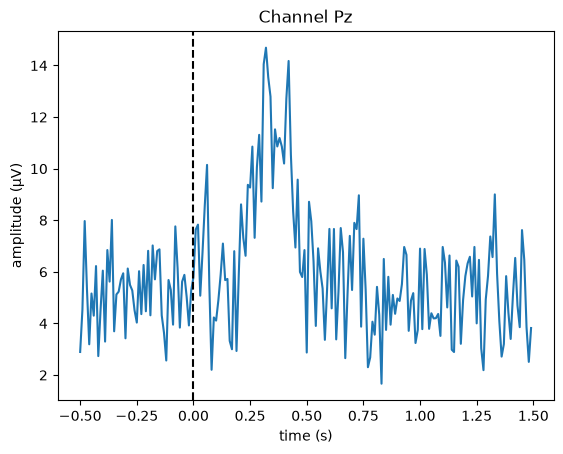

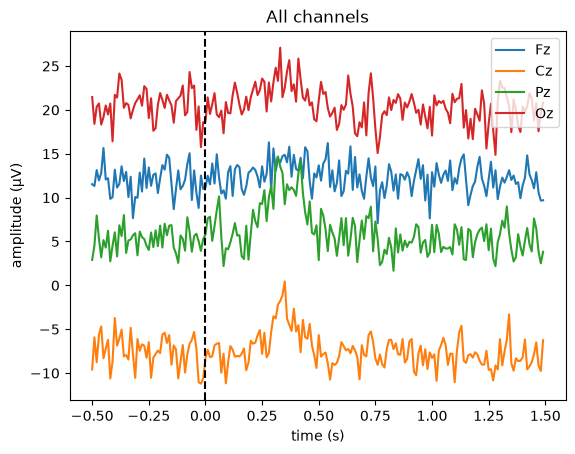

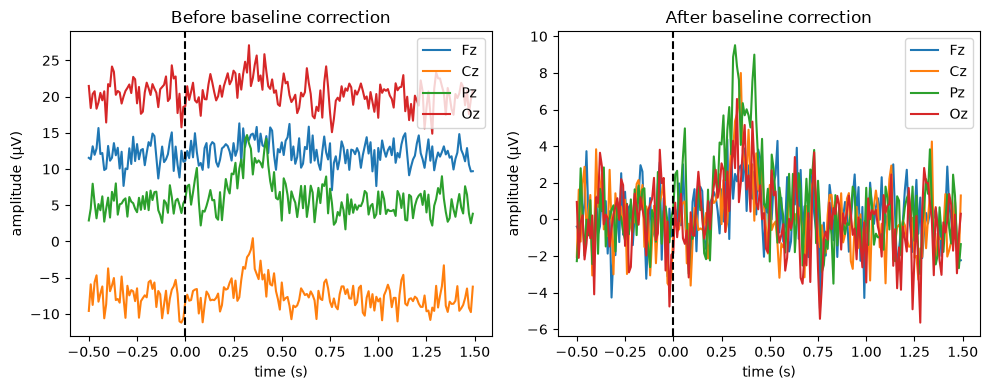

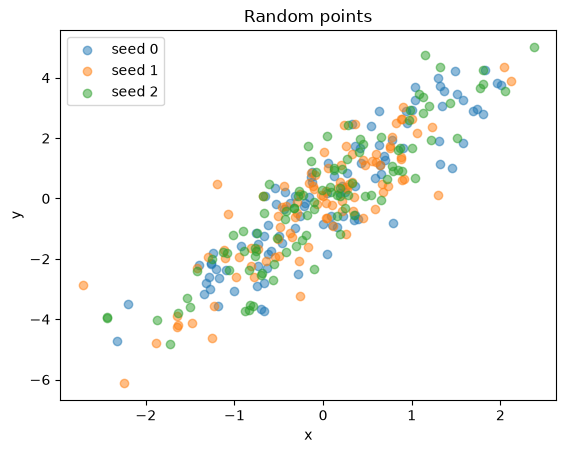

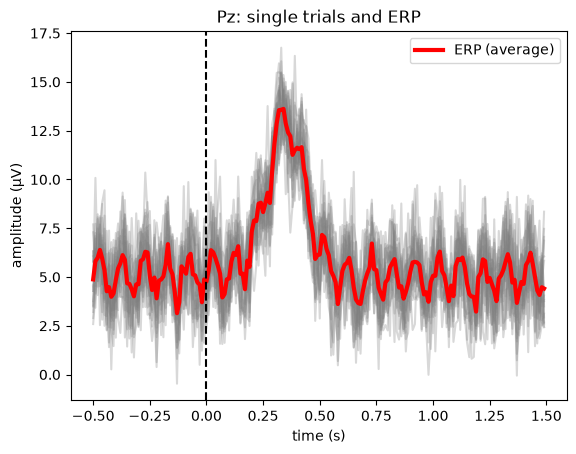

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from eeg_simulation import simulate_eeg

trials, channels, times = simulate_eeg()  # 20 trials x 4 channels x 200 samples
eeg = trials[0]                           # a single trial: 4 channels x 200 samples

# 1. Plot the signal of channel Pz (index 2) over `times`. Label both axes and add a title.
fig, ax = plt.subplots()
ax.plot(times, eeg[2])
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude (µV)")
ax.set_title("Channel Pz")

# 2. Mark the stimulus onset with a dashed vertical line at 0 s.
#    (hint: linestyle="--")
ax.axvline(0, color="black", linestyle="--")

# 3. Plot all four channels into one plot, each with its channel name as label. Add a legend.
#    (hint: a for loop with zip(channels, eeg))
fig, ax = plt.subplots()
for name, signal in zip(channels, eeg):
    ax.plot(times, signal, label=name)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude (µV)")
ax.set_title("All channels")
ax.legend()

# 4. Baseline-correct `eeg` (subtract the mean of the first 50 samples from each channel).
#    Plot the channels before and after the correction in two plots next to each other.
#    What changes?
eeg_corrected = eeg.copy()
for i in range(len(eeg)):
    eeg_corrected[i] = eeg[i] - eeg[i, :50].mean()
# (shorter, without a loop: eeg_corrected = eeg - eeg[:, :50].mean(axis=1, keepdims=True))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, raw, corrected in zip(channels, eeg, eeg_corrected):
    axes[0].plot(times, raw, label=name)
    axes[1].plot(times, corrected, label=name)
axes[0].set_title("Before baseline correction")
axes[1].set_title("After baseline correction")
for ax in axes:
    ax.axvline(0, color="black", linestyle="--")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("amplitude (µV)")
    ax.legend()
fig.tight_layout()
# -> Before, every channel has its own offset (shifted up or down), so the lines are far apart.
#    After the correction, all channels start around 0 µV before the stimulus and can be compared:
#    now you can see that the response around 0.35 s is largest at Pz.

# 5. Save the figure from task 4 as "eeg_baseline.png".
fig.savefig("eeg_baseline.png")

# 6. Write a function `make_random_points(n, seed=0)` that returns two numpy arrays x and y
#    with n values each: x is random, y = 2 * x + random noise.
#    (hint: rng = np.random.default_rng(seed), then rng.normal(0, 1, n))
# ---> Give your function a docstring!
# ---> Use it to make a scatter plot with 100 points. Try different seeds.
def make_random_points(n, seed=0):
    """
    Create n random points where y depends linearly on x.

    x is drawn from a standard normal distribution, y = 2 * x + normal noise.
    The same seed always gives the same points.

    Returns two numpy arrays: x and y (n values each).
    """
    rng = np.random.default_rng(seed)
    x = rng.normal(0, 1, n)
    y = 2 * x + rng.normal(0, 1, n)
    return x, y

fig, ax = plt.subplots()
for seed in [0, 1, 2]:
    x, y = make_random_points(100, seed=seed)
    ax.scatter(x, y, alpha=0.5, label=f"seed {seed}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Random points")
ax.legend()

# 7. Bonus: Plot all 20 trials of Pz in light grey (alpha=0.3) and the average
#    over all trials (the ERP) on top of them as a thick red line (linewidth=3).
pz_trials = trials[:, 2, :]   # all trials, channel Pz, all samples => shape (20, 200)

fig, ax = plt.subplots()
for trial in pz_trials:
    ax.plot(times, trial, color="grey", alpha=0.3)
ax.plot(times, pz_trials.mean(axis=0), color="red", linewidth=3, label="ERP (average)")
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude (µV)")
ax.set_title("Pz: single trials and ERP")
ax.legend()

### seaborn

seaborn works directly with **DataFrames**: you name the DataFrame and the columns, seaborn does the rest.

**Syntax**:

```python
import seaborn as sns

# a default theme
sns.set_theme()
# or your custom settings
sns.set_theme(style="whitegrid", palette='pastel')

# Plots based on data frames
sns.histplot(data=df, x="mood")  # distribution of one column
sns.scatterplot(data=df, x="stress", y="mood")
sns.scatterplot(data=df, x="stress", y="mood", hue="participant_id")  # one color per group
sns.regplot(data=df, x="stress", y="mood")    # scatter plot + regression line
sns.boxplot(data=df, x="location", y="mood")  # one box per group
sns.lineplot(data=df, x="date", y="mood")     # averages per x value + confidence interval

```

seaborn draws on matplotlib **axes**, so everything from matplotlib still works:

```python
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(data=df, x="mood", ax=axes[0])         # draw into the first plot
sns.boxplot(data=df, x="location", y="mood", ax=axes[1])
axes[0].set_title("Mood")

```

**Your tasks ⬇**

75
stress_level
medium    49
low       17
high       9
Name: count, dtype: int64


Text(0.5, 1.0, 'Mood per location')

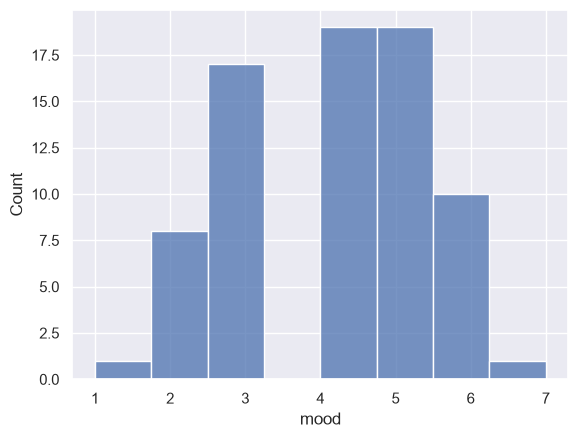

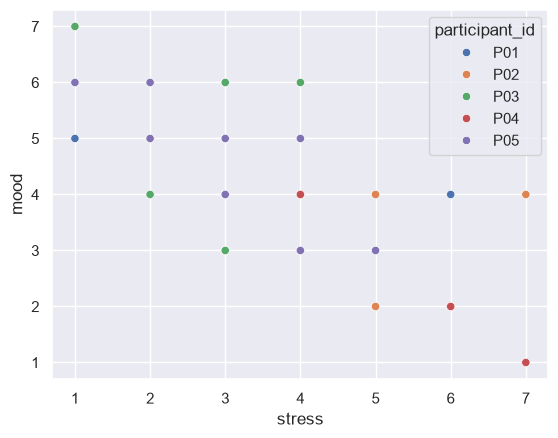

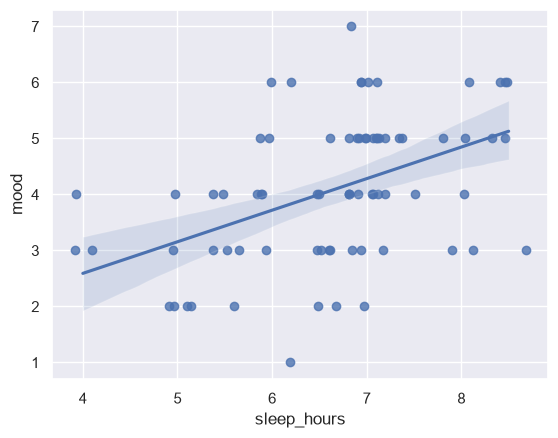

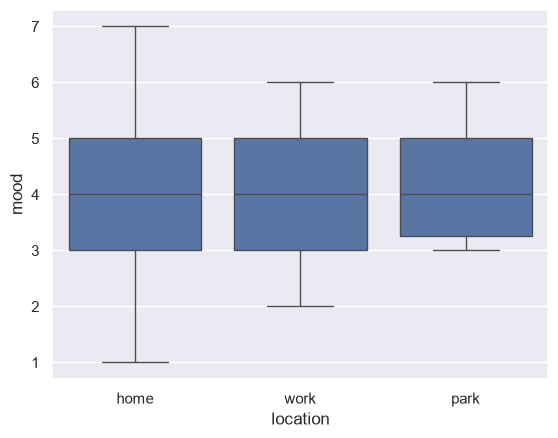

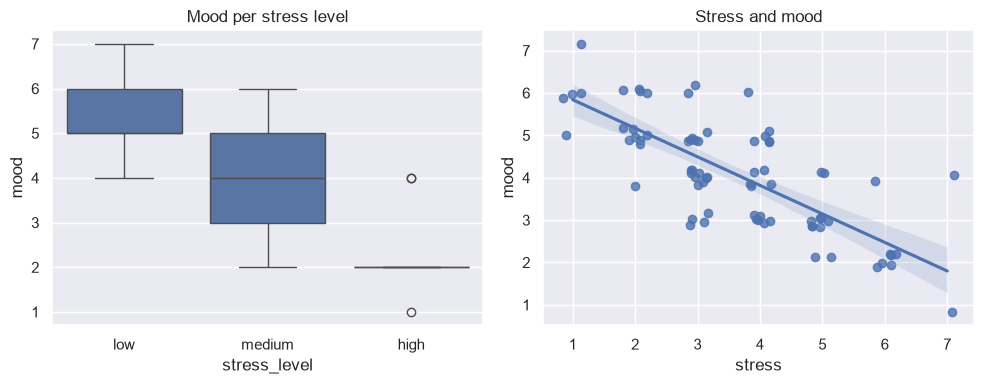

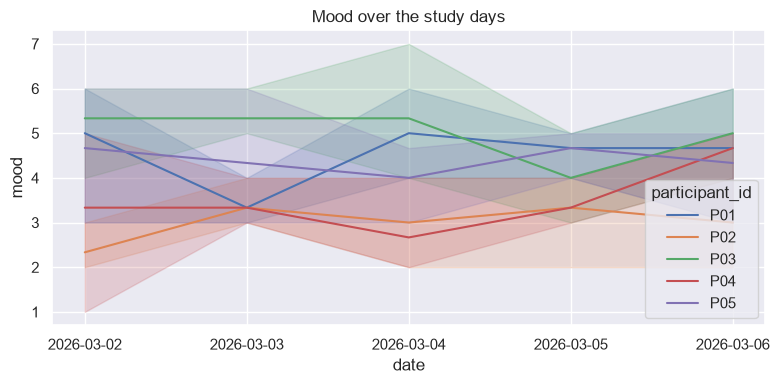

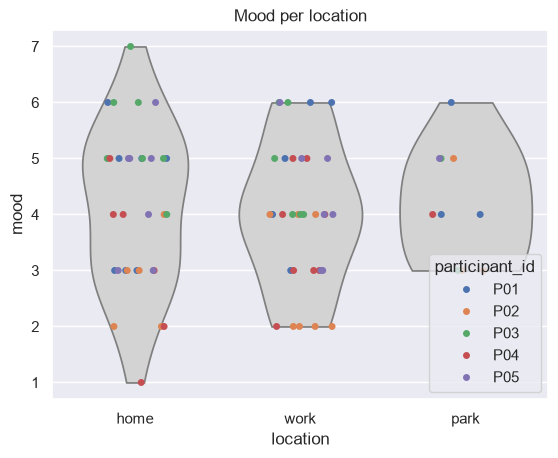

In [2]:
import pandas as pd
import seaborn as sns
from helpers import stress_category

sns.set_theme()

# 1. Load data/esm_simulated.csv into `esm` and clean it: remove the duplicated rows and
#    convert sleep_hours to numbers (careful: it uses decimal commas!).
#    Expected: 75 rows
esm = pd.read_csv("data/esm_simulated.csv")
esm = esm.drop_duplicates()
esm["sleep_hours"] = esm["sleep_hours"].str.replace(",", ".").astype(float)
print(len(esm))

# 2. Plot the distribution of mood as a histogram.
fig, ax = plt.subplots()
sns.histplot(data=esm, x="mood", ax=ax)

# 3. Make a scatter plot of stress (x) against mood (y), one color per participant.
#    What relationship do you see?
fig, ax = plt.subplots()
sns.scatterplot(data=esm, x="stress", y="mood", hue="participant_id", ax=ax)
# -> a negative relationship: the higher the stress, the lower the mood.

# 4. Make a regression plot of sleep_hours (x) against mood (y).
# ---> Many points overlap because the ratings are whole numbers. Try x_jitter=0.2.
fig, ax = plt.subplots()
sns.regplot(data=esm, x="sleep_hours", y="mood", x_jitter=0.2, ax=ax)
# -> x_jitter only moves the dots a little for drawing, the regression line uses the real values.

# 5. Make a box plot of mood per location.
fig, ax = plt.subplots()
sns.boxplot(data=esm, x="location", y="mood", ax=ax)

# 6. Add a column "stress_level" to `esm` with the values "low", "medium" or "high".
#    (hint: the function stress_category() from helpers.py and a list comprehension)
#    Expected: 17 low, 49 medium, 9 high
esm["stress_level"] = [stress_category(s) for s in esm["stress"]]
print(esm["stress_level"].value_counts())

# 7. Combine two plots in one figure: a box plot of mood per stress level and
#    a regression plot of stress against mood. Give both plots a title.
#    (hint: order=["low", "medium", "high"] sorts the boxes)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=esm, x="stress_level", y="mood", order=["low", "medium", "high"], ax=axes[0])
sns.regplot(data=esm, x="stress", y="mood", x_jitter=0.2, y_jitter=0.2, ax=axes[1])
axes[0].set_title("Mood per stress level")
axes[1].set_title("Stress and mood")
fig.tight_layout()

# 8. Bonus: Plot mood over the days for each participant with sns.lineplot().
# ---> There are 3 prompts per day. What does the line show, and what is the shaded area?
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=esm, x="date", y="mood", hue="participant_id", ax=ax)
ax.set_title("Mood over the study days")
fig.tight_layout()
# -> The line shows the AVERAGE of the 3 prompts per day for each participant.
#    The shaded area is the 95 % confidence interval of that average.

# 9. Bonus: Open the seaborn example gallery: https://seaborn.pydata.org/examples/index.html
#    Pick a plot you like and make it with the ESM data.
# Example: violin plots with the single prompts drawn on top
fig, ax = plt.subplots()
sns.violinplot(data=esm, x="location", y="mood", inner=None, color="lightgrey", cut=0, ax=ax)
sns.stripplot(data=esm, x="location", y="mood", hue="participant_id", jitter=0.2, ax=ax)
ax.set_title("Mood per location")

### plotly

`plotly.express` works like seaborn (DataFrame + column names), but the plots are **interactive**: hover over points to see details, drag to zoom, double-click to reset, click on the legend to hide groups.

**Syntax**:

```python
import plotly.express as px

fig = px.scatter(df, x="stress", y="mood", color="participant_id",
                 hover_data=["date", "location"])   # extra info when hovering
fig.show()

px.line(df, x="time", y="Fz") # line plot
px.line(df, x="time", y=["Fz", "Cz"]) # several columns => several lines
px.box(df, x="location", y="mood")
px.histogram(df, x="mood")

fig.write_html("my_plot.html")  # save as an interactive file
```

**Your tasks ⬇**

In [3]:
import plotly.express as px

# 1. Make an interactive scatter plot of stress against mood, one color per participant.
#    Show the date and the location when hovering over a point.
# ---> Try zooming, hovering and hiding participants by clicking on the legend.
fig = px.scatter(esm, x="stress", y="mood", color="participant_id",
                 hover_data=["date", "location"])
fig.show()

# 2. Make an interactive box plot of mood per participant.
fig = px.box(esm, x="participant_id", y="mood")
fig.show()

# 3. Plot the baseline-corrected EEG (from the matplotlib tasks) with plotly:
#    - build a dict with a key "time" for `times` and one key per channel name for its signal
#      (hint: start with {"time": times} and add the channels in a for loop with zip())
#    - turn the dict into a DataFrame
#    - plot all channels with px.line()
#    Expected: a DataFrame with the shape (200, 5)
eeg_dict = {"time": times}
for name, signal in zip(channels, eeg_corrected):
    eeg_dict[name] = signal

eeg_df = pd.DataFrame(eeg_dict)
print(eeg_df.shape)

fig = px.line(eeg_df, x="time", y=channels,
              labels={"time": "time (s)", "value": "amplitude (µV)", "variable": "channel"})
fig.show()

# 4. Save the EEG plot as "eeg.html" and open the file in your browser.
fig.write_html("eeg.html")

# 5. Bonus: Add animation_frame="date" to your scatter plot from task 1 and press play.
#    (hint: sort the DataFrame by date first, and fix the axes with range_x=[0, 8] and range_y=[0, 8])
esm_sorted = esm.sort_values("date")
fig = px.scatter(esm_sorted, x="stress", y="mood", color="participant_id",
                 hover_data=["date", "location"], animation_frame="date",
                 range_x=[0, 8], range_y=[0, 8])
fig.show()

(200, 5)
